# Midterm Exploratory Data Analysis (EDA)
## Wine Recognition Dataset

**Student:** Student Name  
**Course:** Doctorate in Computer Science  
**Assignment:** Midterm — Exploratory Data Analysis  
**Date:** November 2026

---

### Executive Summary
This project performs a detailed exploratory data analysis of the Wine Recognition dataset. The dataset contains **178 wine samples**, **13 numeric chemical measurements**, and a three-class cultivar label. The objective of this midterm is to understand the structure, quality, distributions, relationships, and potential patterns in the data **without building a predictive model**, as required by the assignment.

The analysis includes data inspection, data-quality checks, descriptive statistics, duplicate and missing-value checks, outlier screening using the interquartile range (IQR), an exploratory log transformation, class-level comparisons, correlation analysis, and multiple visualizations. The strongest exploratory differences appear in **flavanoids, OD280/OD315, total phenols, proline, and alcohol**, while the three classes have different distribution profiles.

**Important:** No machine-learning model is trained in this notebook. The work is intentionally limited to EDA and preparation of the dataset for a later modeling phase.

## 1. Dataset Selection and Background

The dataset is the **Wine Recognition dataset**, a copy of the UCI Machine Learning Wine dataset distributed through scikit-learn. It contains chemical-analysis measurements for wines from three different cultivars grown in the same region of Italy. The dataset has 178 observations and 13 numeric attributes, with no missing attribute values. The three classes contain 59, 71, and 48 observations, respectively.

The 13 measurements are: alcohol, malic acid, ash, alcalinity of ash, magnesium, total phenols, flavanoids, nonflavanoid phenols, proanthocyanins, color intensity, hue, OD280/OD315 of diluted wines, and proline.

**Primary EDA questions**
1. What is the overall structure and quality of the dataset?
2. How are observations distributed across the three wine classes?
3. Which chemical measurements show the clearest differences among classes?
4. Which variables have strong relationships with one another?
5. Are there unusual values or skewed distributions that should be considered before future modeling?

**Source:** scikit-learn documentation and the UCI Machine Learning Repository. See References at the end.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

DATA_PATH = 'data/wine_recognition.csv'
df = pd.read_csv(DATA_PATH)
features = [c for c in df.columns if c not in ['target', 'class_name']]

# Preserve readable class labels while retaining the original numeric target.
class_order = ['class_0', 'class_1', 'class_2']
df['class_name'] = pd.Categorical(df['class_name'], categories=class_order, ordered=True)

print(f'Dataset shape: {df.shape}')
display(df.head())

Dataset shape: (178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


## 2. Initial Data Inspection

The first inspection confirms the expected dimensions and allows the variable types and ranges to be checked before analysis. All 13 predictor variables are numeric. The `target` column is an integer class label, while `class_name` is a readable categorical representation.

In [2]:
print('Data types:')
display(df.dtypes.to_frame('dtype'))

print('Descriptive statistics:')
display(df[features].describe().T.round(3))

Data types:


,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


## 3. Data Quality: Missing Values and Duplicates

The assignment asks for transformations and imputations when necessary. In this dataset, **imputation is not necessary** because the source contains no missing attribute values. Duplicate rows are also checked before continuing. If missing values had been present, an imputation strategy would have been documented here rather than silently dropping observations.

In [3]:
missing = df[features].isna().sum().sort_values(ascending=False)
duplicates = df[features].duplicated().sum()

quality_summary = pd.DataFrame({
    'Missing values': missing,
    'Missing %': (missing / len(df) * 100).round(2)
})

print(f'Total duplicated feature rows: {duplicates}')
display(quality_summary)

Total duplicated feature rows: 0


,Missing values,Missing %
alcohol,0,0.0
malic_acid,0,0.0
ash,0,0.0
alcalinity_of_ash,0,0.0
magnesium,0,0.0
total_phenols,0,0.0
flavanoids,0,0.0
nonflavanoid_phenols,0,0.0
proanthocyanins,0,0.0
color_intensity,0,0.0


### Data-quality conclusion
There are **no missing values and no duplicate feature rows**, so no row deletion or imputation is required. The dataset is therefore suitable for exploratory analysis without a missing-data correction step.

## 4. Class Distribution
The class labels are not perfectly balanced: class_1 has the largest number of observations, followed by class_0 and class_2. The imbalance is moderate rather than extreme, but it should still be remembered when interpreting class-level comparisons.

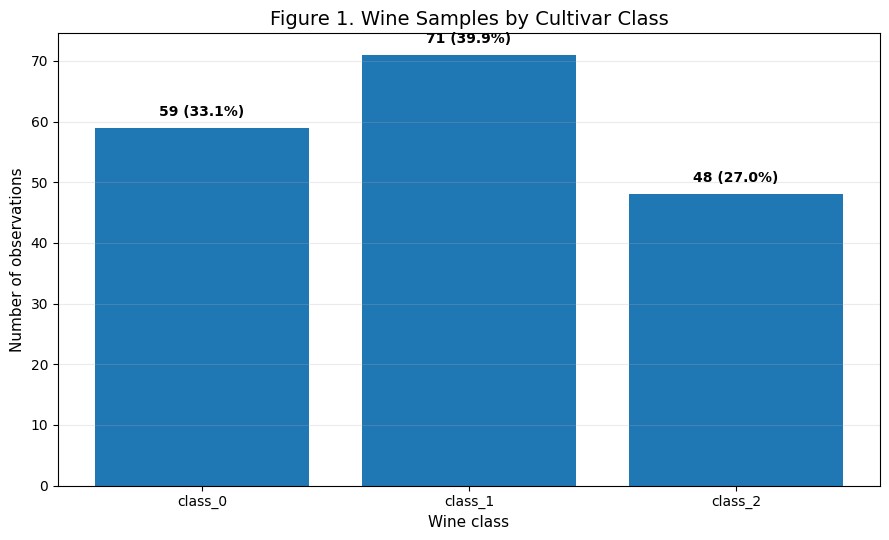

In [4]:
class_counts = df['class_name'].value_counts().reindex(class_order)
class_pct = (class_counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(class_counts.index, class_counts.values)
ax.set_title('Figure 1. Wine Samples by Cultivar Class')
ax.set_xlabel('Wine class')
ax.set_ylabel('Number of observations')
ax.grid(axis='y', alpha=0.25)
for bar, count, pct in zip(bars, class_counts.values, class_pct.values):
    ax.text(bar.get_x()+bar.get_width()/2, count+1.5, f'{count} ({pct}%)', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation.** The largest class is class_1 with 71 observations (39.9%), while class_2 has 48 observations (27.0%). The distribution is sufficiently uneven to note, but not so skewed that one class dominates the dataset.

## 5. Distribution of Key Chemical Variables by Class
To identify variables that may distinguish the three classes, boxplots are used because they display the median, interquartile range, and potential extreme observations without assuming a normal distribution.

/tmp/ipykernel_664/1391027314.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=class_order, patch_artist=True)


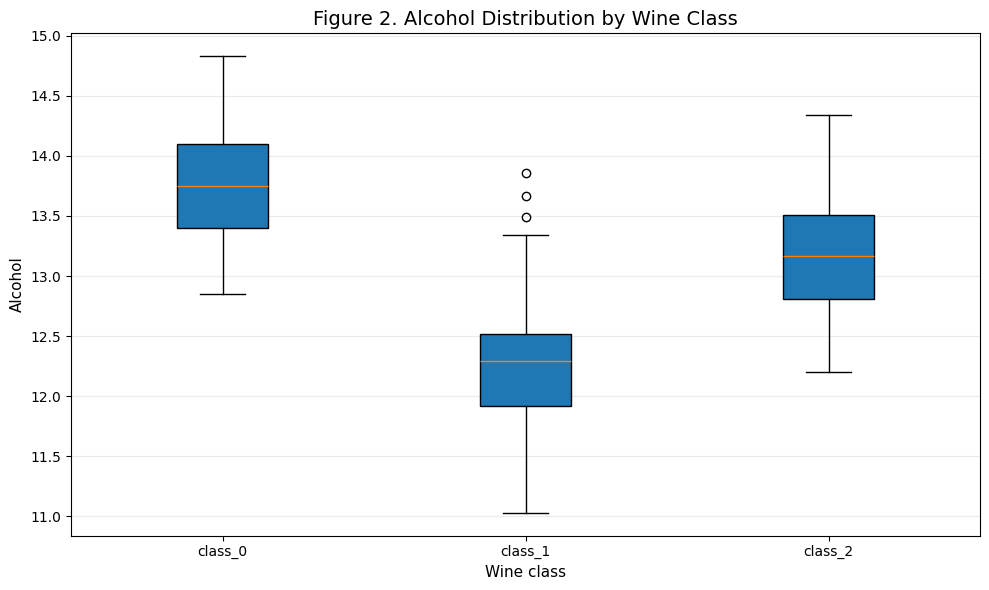

             mean  median   std
class_name                     
class_0     13.74   13.75  0.46
class_1     12.28   12.29  0.54
class_2     13.15   13.16  0.53


/tmp/ipykernel_664/1391027314.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('class_name')['alcohol'].agg(['mean','median','std']).reindex(class_order).round(2))


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
data = [df.loc[df['class_name']==c, 'alcohol'] for c in class_order]
ax.boxplot(data, labels=class_order, patch_artist=True)
ax.set_title('Figure 2. Alcohol Distribution by Wine Class')
ax.set_xlabel('Wine class')
ax.set_ylabel('Alcohol')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(df.groupby('class_name')['alcohol'].agg(['mean','median','std']).reindex(class_order).round(2))

**Interpretation.** Class_0 has the highest average alcohol level (about 13.74), while class_1 has the lowest (about 12.28). Class_2 falls between them. The boxplot also shows that the distributions overlap, meaning alcohol alone does not fully describe the class structure.

/tmp/ipykernel_664/1805789493.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=class_order, patch_artist=True)


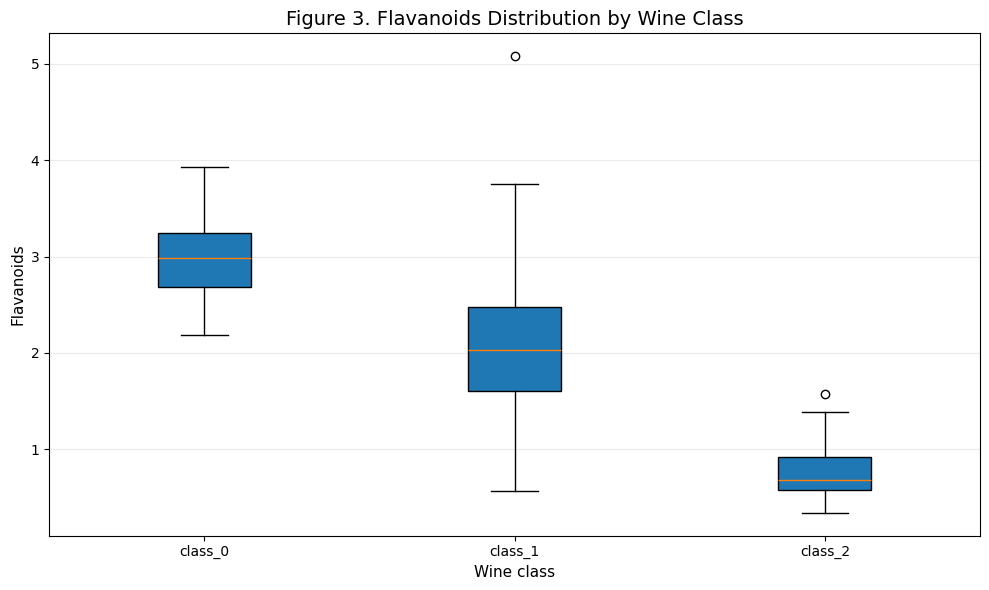

            mean  median   std
class_name                    
class_0     2.98    2.98  0.40
class_1     2.08    2.03  0.71
class_2     0.78    0.68  0.29


/tmp/ipykernel_664/1805789493.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('class_name')['flavanoids'].agg(['mean','median','std']).reindex(class_order).round(2))


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
data = [df.loc[df['class_name']==c, 'flavanoids'] for c in class_order]
ax.boxplot(data, labels=class_order, patch_artist=True)
ax.set_title('Figure 3. Flavanoids Distribution by Wine Class')
ax.set_xlabel('Wine class')
ax.set_ylabel('Flavanoids')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(df.groupby('class_name')['flavanoids'].agg(['mean','median','std']).reindex(class_order).round(2))

**Interpretation.** Flavanoids show a much stronger class-level separation than alcohol. The average is approximately 2.98 for class_0, 2.08 for class_1, and 0.78 for class_2. This makes flavanoids an especially important variable for further investigation in a later modeling phase.

## 6. Multivariate Relationship: Flavanoids and Proline
A scatter plot provides a two-variable view of the data and helps determine whether class structure becomes clearer when two measurements are considered together.

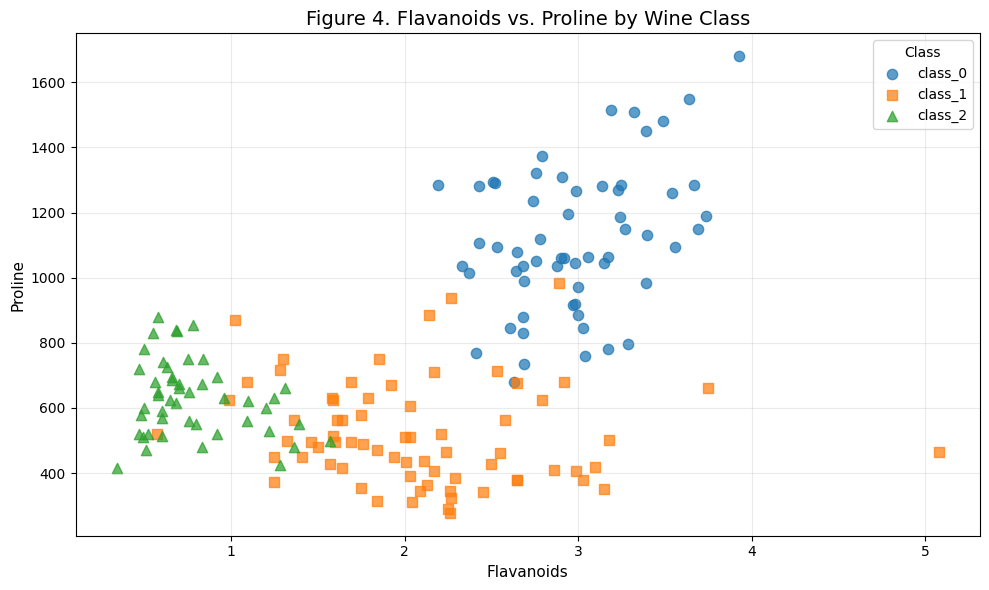

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
for c, marker in zip(class_order, ['o', 's', '^']):
    sub = df[df['class_name']==c]
    ax.scatter(sub['flavanoids'], sub['proline'], alpha=0.72, s=55, marker=marker, label=c)
ax.set_title('Figure 4. Flavanoids vs. Proline by Wine Class')
ax.set_xlabel('Flavanoids')
ax.set_ylabel('Proline')
ax.legend(title='Class')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation.** The scatter plot suggests clear class structure when flavanoids and proline are considered together. Class_0 generally occupies a higher-proline/higher-flavanoid region, while class_2 tends to occupy a lower-flavanoid region. This supports the idea that multiple chemical variables jointly characterize the wine classes.

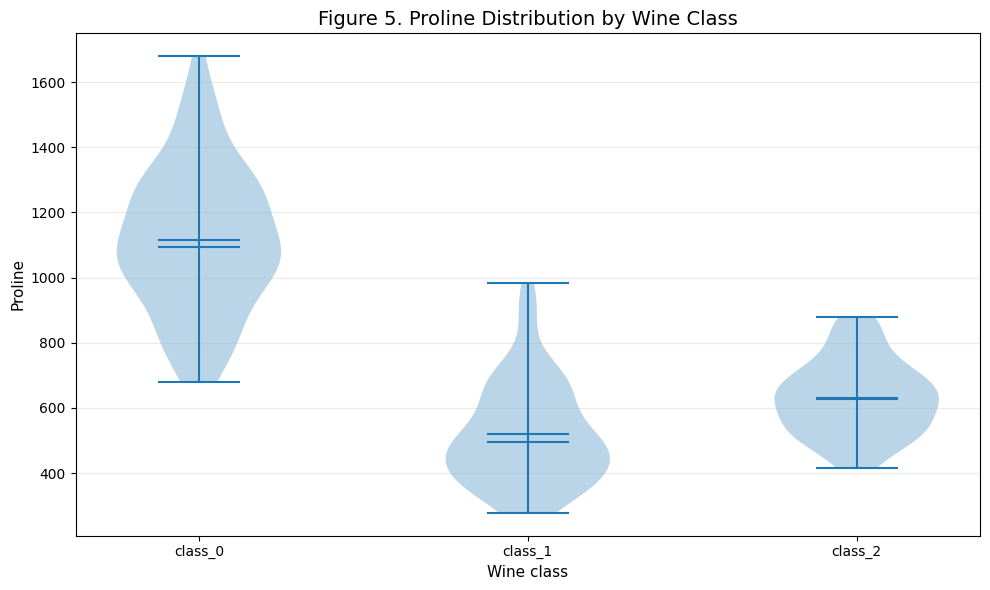

              mean  median    std
class_name                       
class_0     1115.7  1095.0  221.5
class_1      519.5   495.0  157.2
class_2      629.9   627.5  115.1


/tmp/ipykernel_664/937856862.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('class_name')['proline'].agg(['mean','median','std']).reindex(class_order).round(1))


In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
data = [df.loc[df['class_name']==c, 'proline'] for c in class_order]
parts = ax.violinplot(data, showmeans=True, showmedians=True)
ax.set_title('Figure 5. Proline Distribution by Wine Class')
ax.set_xlabel('Wine class')
ax.set_ylabel('Proline')
ax.set_xticks([1,2,3], class_order)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(df.groupby('class_name')['proline'].agg(['mean','median','std']).reindex(class_order).round(1))

**Interpretation.** Proline differs substantially across classes. Class_0 has the highest mean proline concentration (approximately 1,115.7), compared with 519.5 for class_1 and 629.9 for class_2. The violin shapes also show that the distributions are not identical in spread or concentration.

## 7. Correlation Analysis
Correlation analysis is used here as an exploratory tool rather than as evidence of causation. Pearson correlations are calculated among the numeric variables. Strong correlations may indicate redundancy or shared chemical structure and can inform later feature-selection decisions.

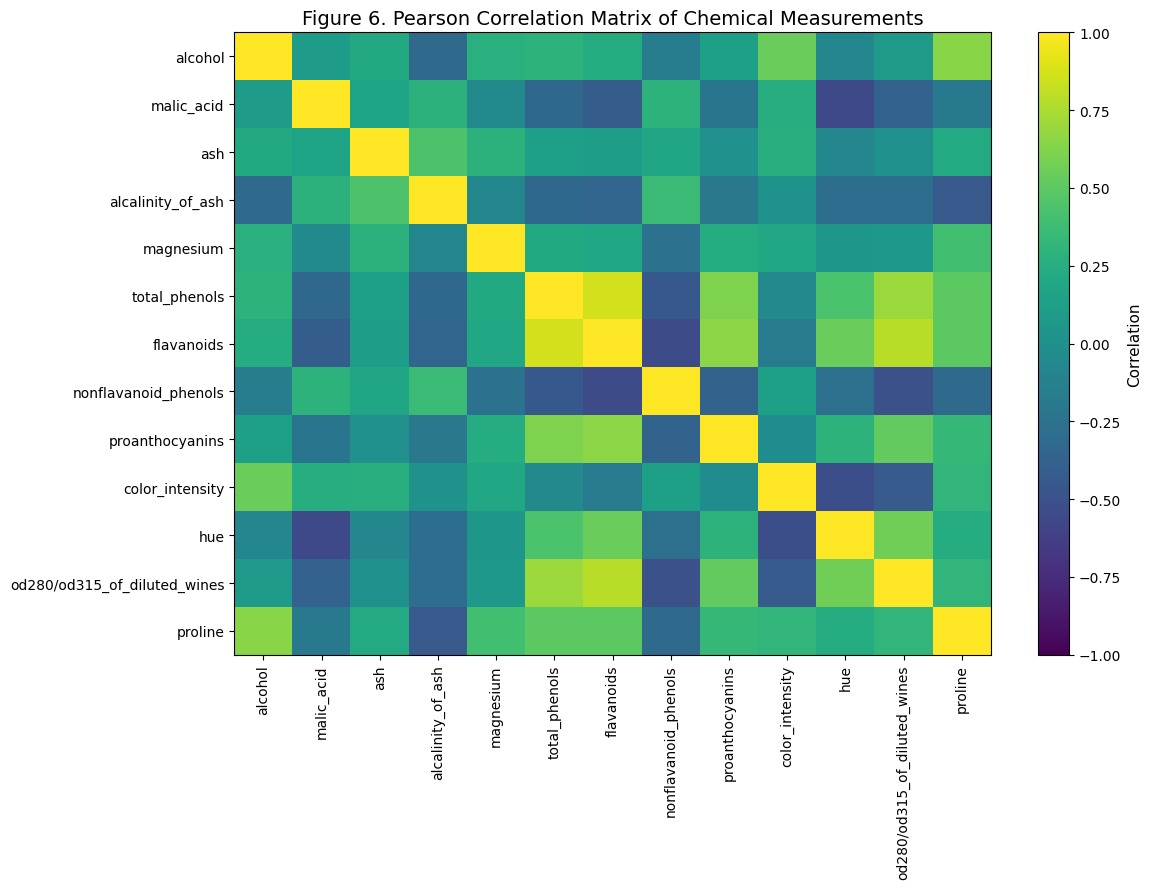

Strongest feature-to-feature correlations:


,,Pearson r
total_phenols,flavanoids,0.865
flavanoids,od280/od315_of_diluted_wines,0.787
total_phenols,od280/od315_of_diluted_wines,0.700
flavanoids,proanthocyanins,0.653
alcohol,proline,0.644
total_phenols,proanthocyanins,0.612
hue,od280/od315_of_diluted_wines,0.565
malic_acid,hue,-0.561
alcohol,color_intensity,0.546
flavanoids,hue,0.543


In [9]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, aspect='auto', vmin=-1, vmax=1)
ax.set_title('Figure 6. Pearson Correlation Matrix of Chemical Measurements')
ax.set_xticks(range(len(features)), features, rotation=90)
ax.set_yticks(range(len(features)), features)
fig.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()

# Strongest absolute correlations excluding the diagonal.
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(key=np.abs, ascending=False)
print('Strongest feature-to-feature correlations:')
display(pairs.head(10).to_frame('Pearson r').round(3))

**Interpretation.** Several variables show strong relationships. In particular, flavanoids, total phenols, and OD280/OD315 are closely related. This suggests that some measurements capture overlapping aspects of the chemical profile. Correlation is useful for identifying such structure, but it does not establish causality.

## 8. Outlier Screening Using the IQR Rule
Potential outliers are screened using the standard 1.5 × IQR rule. The purpose at this stage is not to automatically delete observations, but to identify variables that deserve closer inspection. In EDA, extreme values may be legitimate measurements rather than errors.

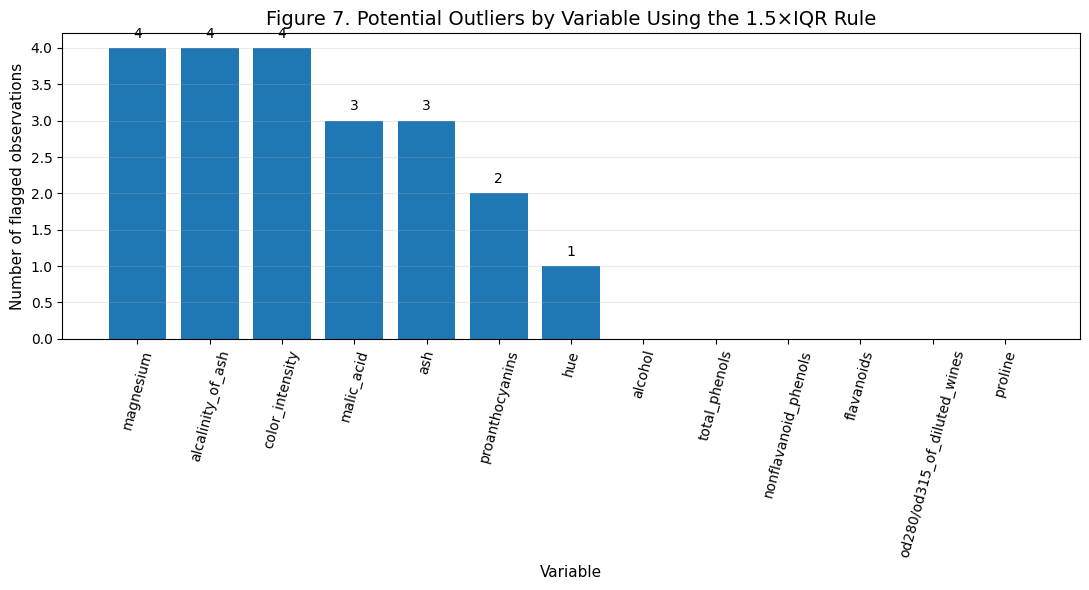

,IQR outlier count
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0
total_phenols,0
nonflavanoid_phenols,0


In [10]:
outlier_counts = {}
for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_counts[col] = int(((df[col] < lower) | (df[col] > upper)).sum())

outlier_series = pd.Series(outlier_counts).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(outlier_series.index, outlier_series.values)
ax.set_title('Figure 7. Potential Outliers by Variable Using the 1.5×IQR Rule')
ax.set_xlabel('Variable')
ax.set_ylabel('Number of flagged observations')
ax.tick_params(axis='x', rotation=75)
ax.grid(axis='y', alpha=0.25)
for b, v in zip(bars, outlier_series.values):
    if v > 0:
        ax.text(b.get_x()+b.get_width()/2, v+0.1, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.show()

display(outlier_series.to_frame('IQR outlier count'))

**Interpretation.** The IQR screen identifies the largest number of potential extreme observations in alcalinity of ash, magnesium, color intensity, and malic acid. These observations are **not removed** because the dataset documentation does not indicate that they are data-entry errors. Future modeling should evaluate whether robust methods or transformations are appropriate.

## 9. Transformation Check: Proline
The assignment asks for transformations when necessary. Proline is right-skewed, so a `log1p` transformation is demonstrated as an exploratory comparison. The original variable is retained; the transformed value is not used to build a model.

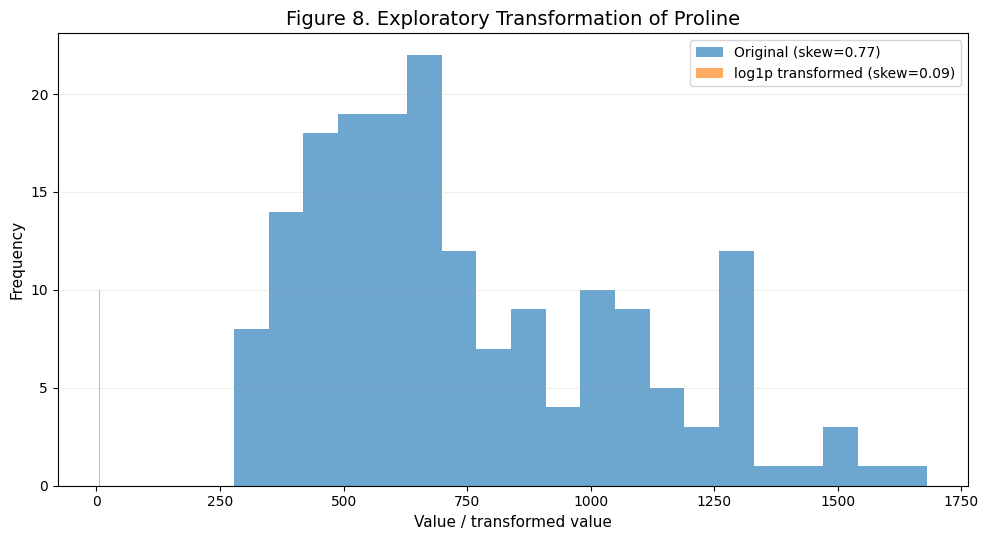

Proline skewness before transformation: 0.768
Proline skewness after transformation:  0.088


In [11]:
proline_skew_before = df['proline'].skew()
df['log1p_proline'] = np.log1p(df['proline'])
proline_skew_after = df['log1p_proline'].skew()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(df['proline'], bins=20, alpha=0.65, label=f'Original (skew={proline_skew_before:.2f})')
ax.hist(df['log1p_proline'], bins=20, alpha=0.65, label=f'log1p transformed (skew={proline_skew_after:.2f})')
ax.set_title('Figure 8. Exploratory Transformation of Proline')
ax.set_xlabel('Value / transformed value')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

print(f'Proline skewness before transformation: {proline_skew_before:.3f}')
print(f'Proline skewness after transformation:  {proline_skew_after:.3f}')

**Interpretation.** The log transformation reduces the influence of the long right tail in proline. This is a useful candidate preprocessing step for a later statistical or machine-learning analysis, although the original scale remains valuable for interpretation.

## 10. Standardized Class Profiles
The chemical variables have very different units and scales. To compare the **shape of class-level profiles** on a common scale, each variable is standardized using the overall sample mean and standard deviation. This is a descriptive visualization only; it is not a model.

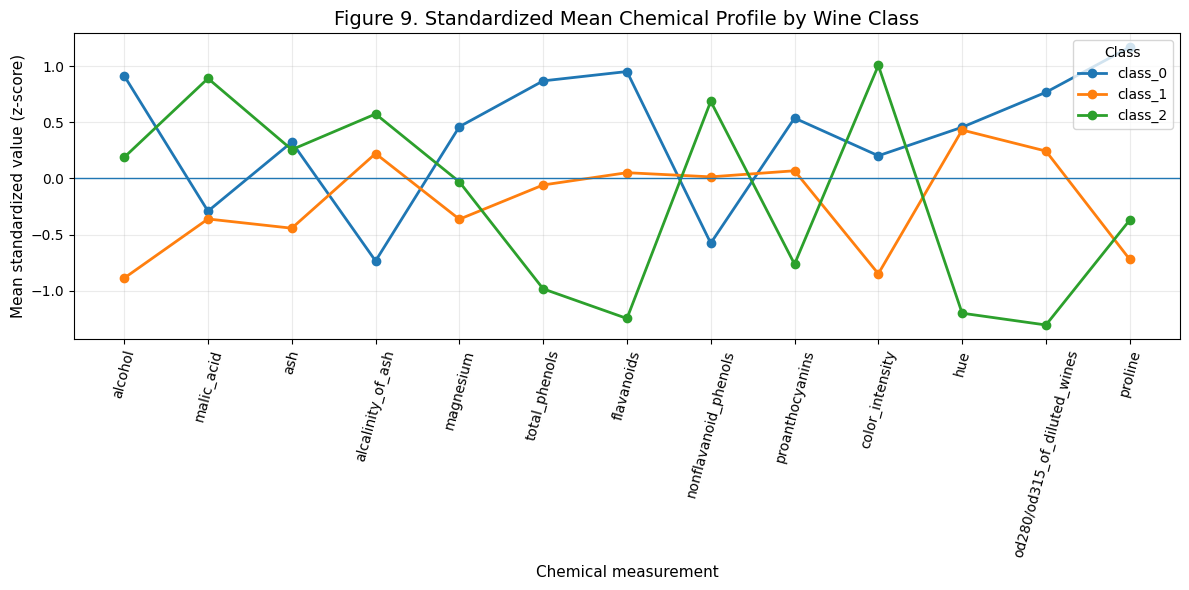

In [12]:
X = df[features].copy()
X_z = (X - X.mean()) / X.std(ddof=1)
profile = X_z.assign(class_name=df['class_name']).groupby('class_name', observed=True).mean().reindex(class_order)

fig, ax = plt.subplots(figsize=(12, 6))
for c in class_order:
    ax.plot(features, profile.loc[c], marker='o', linewidth=2, label=c)
ax.axhline(0, linewidth=1)
ax.set_title('Figure 9. Standardized Mean Chemical Profile by Wine Class')
ax.set_xlabel('Chemical measurement')
ax.set_ylabel('Mean standardized value (z-score)')
ax.tick_params(axis='x', rotation=75)
ax.legend(title='Class')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation.** The standardized profile highlights how differently the three classes behave across the full set of measurements. Class_0 is especially high in proline, flavanoids, and total phenols; class_2 is relatively high in color intensity and nonflavanoid phenols; class_1 tends to be lower on several phenolic measures. The multivariate profile is more informative than any single variable alone.

## 11. Key Findings and Data-Preparation Recommendations

### Main findings
- The dataset contains **178 observations and 13 numeric chemical measurements**, plus a three-level class label.
- Class distribution is **59 class_0, 71 class_1, and 48 class_2**.
- There are **no missing values** and **no duplicate feature rows**, so imputation and duplicate removal are unnecessary.
- Flavanoids show pronounced differences among the three classes, with class means of approximately **2.98, 2.08, and 0.78** for class_0, class_1, and class_2, respectively.
- Proline also differs strongly by class, with the highest mean in class_0.
- Several chemical measurements are strongly correlated, indicating possible redundancy among variables.
- IQR screening flags a limited number of potential extreme observations, especially for alcalinity of ash, magnesium, color intensity, and malic acid.
- Proline is right-skewed; a log transformation reduces the skewness and could be considered in later analysis.

### Recommendations for the next project phase
1. Preserve the original data and document every preprocessing step.
2. Investigate flagged outliers individually before deciding whether to retain, transform, or remove them.
3. Consider standardized features for methods that are sensitive to variable scale.
4. Evaluate correlated variables carefully to avoid unnecessary redundancy.
5. Use stratified train/test splitting if a classification model is built later because class sizes are not identical.

**No predictive model was built in this midterm.** The purpose of this submission is EDA and data preparation only.

## 12. Conclusion

The Wine Recognition dataset is clean, compact, and well suited for a detailed exploratory analysis. The EDA shows that wine classes differ substantially across several chemical measurements, particularly flavanoids, proline, phenolic measurements, and alcohol. The analysis also identifies correlations, possible outliers, and a useful transformation candidate. These findings provide a strong foundation for a later modeling phase while respecting the midterm requirement not to build models at this stage.

## References

Aeberhard, S., & Forina, M. (1992). *Wine* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (2026). *Wine recognition dataset*. Scikit-learn documentation. https://sklearn.org/stable/modules/generated/sklearn.datasets.load_wine.html

UCI Machine Learning Repository. (1991). *Wine*. https://archive.ics.uci.edu/dataset/109/wine